# NanoTox regression model developemnt
Author: Chi-Yun Chen

Date: November 17, 2026

Description: Modeling-regression task

In [1]:
#Install basic python pcakges
import numpy as np
import pandas as pd

In [2]:
Cytotox = pd.read_csv('NanoTox_9338.csv')
Cytotox.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9338 entries, 0 to 9337
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Cytotoxicity       9338 non-null   object 
 1   Core               9338 non-null   object 
 2   Surf_func          9338 non-null   object 
 3   Assay_viability    9338 non-null   object 
 4   Cell_morphol       9338 non-null   object 
 5   Cell_type          9338 non-null   object 
 6   Tumor_cell         9338 non-null   object 
 7   Cell_source        9338 non-null   object 
 8   Cell_culture       9338 non-null   object 
 9   Cell_age           9338 non-null   object 
 10  Diameter           9338 non-null   float64
 11  Time               9338 non-null   float64
 12  Concentration      9338 non-null   float64
 13  Mol_weight         9338 non-null   float64
 14  Electronegativity  9338 non-null   float64
 15  Dh_median          9338 non-null   float64
 16  ZP_median          9338 

In [3]:
# Binary Encoding for columns with Number of unique values = 2 (reduce dimentionality)
Cytotox['Cell_age'] = Cytotox['Cell_age'].map({'Embryonic': 1, 'NonEmbryonic': 0})
Cytotox['Cell_culture'] = Cytotox['Cell_culture'].map({'primary': 1, 'cell_line': 0})

In [4]:
# Binary Encoding for columns with Number of unique values = 2 (reduce dimentionality)
Cytotox['Tumor_cell'] = Cytotox['Tumor_cell'].map({'Yes': 1, 'No': 0})

In [5]:
v = Cytotox['Cell_viability']

Q1, Q3 = np.nanpercentile(v, [25, 75])
IQR = Q3 - Q1

K = 0.5  # standard Tukey upper fence; change only if you deliberately want tighter
global_cap = Q3 + K * IQR

print(f"Q1 = {Q1:.3f}, Q3 = {Q3:.3f}, IQR = {IQR:.3f}")
print(f"Global cap = Q3 + {K} x IQR = {global_cap:.3f}")

Q1 = 49.000, Q3 = 97.482, IQR = 48.482
Global cap = Q3 + 0.5 x IQR = 121.723


In [6]:
#  Cap viability at 120%  <-- 97.5th percentile of the 7,252 raw values
n_capped = int((v > 120).sum())
Cytotox['Cell_viability'] = v.clip(upper=120)
print(f"Capped {n_capped} rows at {global_cap:.3f}")
print(f"New max: {Cytotox['Cell_viability'].max():.3f}") 

Capped 176 rows at 121.723
New max: 120.000


# Regression Model

In [7]:
Viability_cleaned = Cytotox.drop(columns=Cytotox.columns[[0]])

In [8]:
Viability_7074 = Viability_cleaned.dropna()
Viability_7074.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7074 entries, 430 to 9337
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Core               7074 non-null   object 
 1   Surf_func          7074 non-null   object 
 2   Assay_viability    7074 non-null   object 
 3   Cell_morphol       7074 non-null   object 
 4   Cell_type          7074 non-null   object 
 5   Tumor_cell         7074 non-null   int64  
 6   Cell_source        7074 non-null   object 
 7   Cell_culture       7074 non-null   int64  
 8   Cell_age           7074 non-null   int64  
 9   Diameter           7074 non-null   float64
 10  Time               7074 non-null   float64
 11  Concentration      7074 non-null   float64
 12  Mol_weight         7074 non-null   float64
 13  Electronegativity  7074 non-null   float64
 14  Dh_median          7074 non-null   float64
 15  ZP_median          7074 non-null   float64
 16  Cell_viability     7074 non

## Step 1: remove duplicated rows

In [9]:
# 1) IDENTIFY: every row that is part of an exact-duplicate set
dup_mask_all = Viability_7074.duplicated(keep=False)
print('rows involved in exact duplicates:', dup_mask_all.sum())

# excess copies only (this is how many rows dropping will remove)
print('rows to be removed:', Viability_7074.duplicated(keep='first').sum())

# inspect them grouped together before you drop anything
dup_rows = Viability_7074[dup_mask_all].sort_values(by=list(Viability_7074.columns))
print(dup_rows)

rows involved in exact duplicates: 97
rows to be removed: 53
      Core   Surf_func Assay_viability Cell_morphol Cell_type  Tumor_cell  \
6402    Ag         PVP       CalceinAM   fibroblast      hMSC           0   
6409    Ag         PVP       CalceinAM   fibroblast      hMSC           0   
1967  SiO2  Unmodified       Annexin_V   epithelial      HeLa           1   
2003  SiO2  Unmodified       Annexin_V   epithelial      HeLa           1   
1969  SiO2  Unmodified       Annexin_V   epithelial      HeLa           1   
...    ...         ...             ...          ...       ...         ...   
1240  SiO2  Unmodified           WST_1   epithelial      HT29           1   
3863  SiO2  Unmodified           WST_1   epithelial     HepG2           1   
3879  SiO2  Unmodified           WST_1   epithelial     HepG2           1   
1432  SiO2  Unmodified      alamarBlue   epithelial      A549           1   
1436  SiO2  Unmodified      alamarBlue   epithelial      A549           1   

     Cell_sour

In [10]:
# 2) DROP: keep the first occurrence of each set
Viability_dedup1 = Viability_7074.drop_duplicates(keep='first').copy()
print('before:', len(Viability_7074), 'after:', len(Viability_dedup1))

before: 7074 after: 7021


## Step 2: Data preparation

In [11]:
# Columns to be transformed via one-hot encoding
columns_to_encode = ["Core", "Surf_func", "Assay_viability", "Cell_morphol", "Cell_type", "Cell_source"]

# Perform one-hot encoding
Viability_encoded = pd.get_dummies(Viability_dedup1, columns=columns_to_encode, drop_first=True)

In [12]:
# Where 'Cell_morphol_spindle, epithelial' = True, set both columns to True
mask = Viability_encoded['Cell_morphol_spindle, epithelial'] == True

Viability_encoded.loc[mask, 'Cell_morphol_spindle'] = True
Viability_encoded.loc[mask, 'Cell_morphol_epithelial'] = True

# Step 2: Drop the combined column
Viability_encoded = Viability_encoded.drop(columns=['Cell_morphol_spindle, epithelial'])

In [13]:
# Converts True to 1 and False to 0 wherever they appear
viability = Viability_encoded.map(lambda x: int(x) if isinstance(x, bool) else x)

In [14]:
viability.head()

,Tumor_cell,Cell_culture,Cell_age,Diameter,Time,Concentration,Mol_weight,Electronegativity,Dh_median,ZP_median,...,Cell_type_mDF,Cell_type_primary mixed neurons,Cell_source_Dog,Cell_source_Hamster,Cell_source_Human,Cell_source_Monkey,Cell_source_Mouse,Cell_source_Pig,Cell_source_Rabbit,Cell_source_Rat
430,0,0,0,10.0,24.0,10.0,60.083,2.926667,63.0,-25.0,...,0,0,0,0,1,0,0,0,0,0
431,0,0,0,10.0,24.0,20.0,60.083,2.926667,63.0,-25.0,...,0,0,0,0,1,0,0,0,0,0
432,0,0,0,10.0,24.0,50.0,60.083,2.926667,63.0,-25.0,...,0,0,0,0,1,0,0,0,0,0
433,0,0,0,10.0,24.0,60.0,60.083,2.926667,63.0,-25.0,...,0,0,0,0,1,0,0,0,0,0
434,0,0,0,10.0,24.0,70.0,60.083,2.926667,63.0,-25.0,...,0,0,0,0,1,0,0,0,0,0


## Step 3: Split dataframe to X and y

In [15]:
rY_2d = viability.loc[:, ['Cell_viability']]
# Convert Y as a column vector to a 1D array
rY = rY_2d.values.ravel()
print(rY.shape)

(7021,)


In [16]:
# X features
rX = viability.iloc[:, viability.columns != 'Cell_viability']
print(rX.shape)

(7021, 255)


In [17]:
variance = rX.var()
rX = rX.loc[:, variance != 0]
print(rX.shape)

(7021, 255)


In [18]:
# Group columns with identical values
groups = []
checked = set()

for col in rX.columns:
    if col in checked:
        continue
    group = [col]
    for other_col in rX.columns:
        if other_col != col and other_col not in checked:
            if rX[col].equals(rX[other_col]):
                group.append(other_col)
    if len(group) > 1:
        groups.append(group)
        checked.update(group)

print("Groups of identical columns:")
for g in groups:
    print(g)

Groups of identical columns:
['Core_Cu', 'Surf_func_AscorbicAcid', 'Cell_type_HGF']
['Surf_func_CCK_peptide', 'Cell_type_primary mixed neurons']
['Assay_viability_Relative_total_growth', 'Cell_type_L5178Y/Tk+/_ -3.7.2C']
['Cell_morphol_keratinocyte', 'Cell_type_HaCaT']
['Cell_morphol_myoblast', 'Cell_type_H9c2']
['Cell_type_MDCK', 'Cell_source_Dog']
['Cell_type_PK15', 'Cell_source_Pig']
['Cell_type_SIRC', 'Cell_source_Rabbit']
['Cell_type_Vero', 'Cell_source_Monkey']


In [19]:
for group in groups:
    # Keep the first, drop the rest
    rX.drop(columns=group[1:], inplace=True)

In [20]:
print(rX.shape)

(7021, 245)


In [21]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm  # Import the colormap module
from sklearn.manifold import TSNE
from pypalettes import load_cmap
from pypalettes import create_cmap

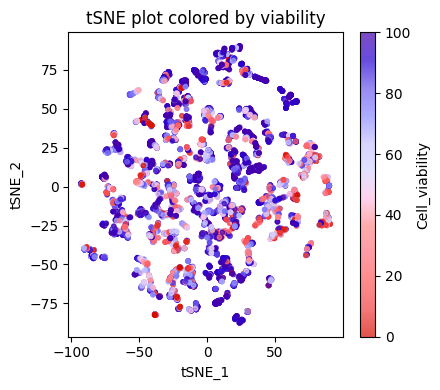

In [22]:
# Compute t-SNE embedding
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(rX)

# Plot
fig, ax = plt.subplots(figsize=(4.5,4))
sc = ax.scatter(
    X_embedded[:,0], X_embedded[:,1],
    c=rY, cmap = load_cmap("default_gsea", cmap_type="continuous", reverse=True),
    vmin=0, vmax=100,   # clip color scale
    s=10, alpha=0.7
)
plt.colorbar(sc, label='Cell_viability')

ax.set_xlabel('tSNE_1')
ax.set_ylabel('tSNE_2')
ax.set_title('tSNE plot colored by viability')
plt.tight_layout()

plt.show()

## Step 3: Build Machine Learning Modeling Pipeline

In [23]:
!pip install imblearn
!pip install catboost
!pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [24]:
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from catboost import CatBoostRegressor
from sklearn.neighbors import KNeighborsRegressor     
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.svm import SVR          
from sklearn.neural_network import MLPRegressor
from scipy.stats import loguniform, uniform, randint
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error, root_mean_squared_error     
from sklearn.metrics import mean_squared_error         # Mean Squared Error metric

import warnings                                               # Warning control
warnings.filterwarnings("ignore")   
import joblib
from joblib import dump, load

import os
import matplotlib.pyplot as plt
import matplotlib.cm as cm             # Import the colormap module

<frozen importlib._bootstrap>:241: RuntimeWarning: numpy.ufunc size changed, may indicate binary incompatibility. Expected 216 from C header, got 232 from PyObject


In [25]:
# Define hyperparameter grids

# Catboost parameter distribution for hyperparameter tuning: 
# A gradient boosting model similar to XGBoost and LightGBM, 
# but it often handles categorical and imbalanced data better
catboost_parm_search = {
    'iterations': randint(50, 300),          # Number of boosting iterations
    'depth': randint(3, 11),                 # Depth of the tree
    'learning_rate': uniform(0.1, 0.3),      # Learning rate
    'l2_leaf_reg': uniform(1, 2),            # L2 regularization
    'bagging_temperature': uniform(0, 1),    # Bagging temperature
    'random_strength': uniform(0, 1)
}

# Gradient Boosting parameter distribution for hyperparameter tuning
GB_parm_search = {
    'n_estimators': randint(100, 300), 
    'learning_rate': uniform(0.1, 0.3),     
    'max_depth': randint(3, 9),     
    'min_samples_split': randint(2, 15),   
    'min_samples_leaf': randint(1, 4)
}

# RandomForest parameter distribution for hyperparameter tuning
rf_parm_search = {
    'n_estimators': randint(30, 150),       # Number of trees in the forest
    'max_depth': randint(5, 60),            # Maximum depth of the trees
    'min_samples_split': randint(2, 15),    # Minimum number of samples required to split an internal node
    'min_samples_leaf': randint(1, 5),      # Minimum number of samples required to be a leaf node
    'max_features': ['sqrt', 'log2', 0.3, 0.5, 0.7, 0.9],
    'bootstrap': [True, False]              # Whether to bootstrap samples
}

# XGBoost parameter distribution for hyperparameter tuning
XGB_parm_search = {
    'eta': uniform(0.05, 0.5),          # learning_rate
    'gamma': uniform(0, 10),            # min_split_loss
    'max_depth': randint(3, 13),     
    'min_child_weight': randint(1, 10),    # Minimum sum of instance weight (hessian) needed in a child
    'colsample_bytree': uniform(0.6, 0.4),
    'n_estimators': randint(100, 500),
    'subsample': uniform(0.6, 0.4)
}

# KNN parameter distribution for hyperparameter tuning
KNN_parm_search = {
    'n_neighbors': randint(2, 16),       # Number of neighbors  # avoid k=1 (overfitting)
    'weights': ['uniform', 'distance'],  # Weight function used in prediction
}

# SVM parameters distribution for hyperparameter tuning  
SVM_parm_search = {      #'kernel': ['rbf'],  # 'poly' get negative r2; 'sigmoid' get r2 <0.2
    'C': loguniform(1e-1, 1e2),      # Regularization parameter
    'epsilon': uniform(1e-3, 1e-1),
    'gamma':[1e-3, 1e-2, 0.1, 'scale', 'auto'],
}

NN_parm_search = {
    'hidden_layer_sizes': [(128,), (256,), (64, 32), (100, 50), (128, 64),
                           (200, 64), (200, 150), (256, 128), (256, 200)],
    'activation': ['relu', 'tanh', 'logistic'],
    #'solver': ['adam'],
    'alpha': np.logspace(-4, -1, 7),    # L2 regularization
}

# Define models
models = {
    'CatBoost': (CatBoostRegressor(verbose=False, thread_count=1), catboost_parm_search),
    'GB': (GradientBoostingRegressor(), GB_parm_search),
    'RF': (RandomForestRegressor(), rf_parm_search),
    'XGB': (XGBRegressor(n_jobs=1), XGB_parm_search),
    'KNN': (KNeighborsRegressor(), KNN_parm_search),
    'SVM': (SVR(), SVM_parm_search),
    'NN': (MLPRegressor(max_iter=4000, early_stopping=True, n_iter_no_change=25, random_state=42), NN_parm_search),
    }

#KNN, logistic regression, and neural networks are sensitive to the scale of numerical features
###SVC running indefinitely no matter data are scaling or not.

80% train, 20% test
Cross validation by using StratifiedKFold to ensure that each fold maintains the same proportion of classes as in the original dataset

In [26]:
# Symmetric Mean Absolute Percentage Error: (100% / n) · ∑ᵢ[2·|ŷᵢ – yᵢ|/(|yᵢ| + |ŷᵢ|)]
def smape(y_true, y_pred, eps=1e-8):
    num = np.abs(y_pred - y_true) * 2
    den = np.abs(y_true) + np.abs(y_pred) + eps
    return 100 * np.mean(num / den)

# Weighted Mean Absolute Percentage Error: 100% · ∑ᵢ|ŷᵢ – yᵢ|/∑ᵢ|yᵢ|
def wmape(y_true, y_pred, eps=1e-8):
    num = np.abs(y_pred - y_true)
    den = np.abs(y_true).sum() + eps
    return 100 * np.sum(num) / den

In [27]:
print(type(rX))

<class 'pandas.core.frame.DataFrame'>


In [28]:
# Fit and transform only numerical features 
#'Diameter', 'Time', 'Concentration', 'Mol_weight', 'Electronegativity', 'Dh_median', 'ZP_median'
binary_features = [
    col for col in rX.columns
    if set(rX[col].dropna().unique()).issubset({0, 1})
]

numerical_features = [
    col for col in rX.columns
    if col not in binary_features
]

In [29]:
# Hyperparameter tuning for classical algorithms
TREE_BASED = {"CatBoost", "GB", "RF", "XGB"}
METRIC_NAMES = ("mse", "rmse", "mae", "smape", "wmape", "r2")


def make_pipeline(model_name, model, param_search):
    """Tree models: no scaling. Others: numerical-only scaling, binaries passthrough."""
    if model_name in TREE_BASED:
        return model, param_search
    preprocessor = ColumnTransformer(
        transformers=[("num", StandardScaler(), numerical_features)],
        remainder="passthrough",
    )
    pipeline = Pipeline([("preprocessor", preprocessor), ("clf", model)])
    pipe_params = {f"clf__{k}": v for k, v in param_search.items()}
    return pipeline, pipe_params


def compute_metrics(y_true, y_pred):
    mse_val = mean_squared_error(y_true, y_pred)
    return {
        "mse": mse_val,
        "rmse": np.sqrt(mse_val),
        "mae": mean_absolute_error(y_true, y_pred),
        "smape": smape(y_true, y_pred),
        "wmape": wmape(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }


def nested_cv(X, y, model_name, random_state=42, n_iter=100):
    """
    Nested CV: inner loop tunes hyperparameters, outer loop evaluates.
    Metrics: MSE, RMSE, MAE, SMAPE, WMAPE, R2.
    Returns aggregated train/test metrics (mean, std) over outer folds.
    Train metrics are in-sample (best model evaluated on its own outer train set).
    """
    model, param_search = models[model_name]
    pipeline, pipe_params = make_pipeline(model_name, model, param_search)

    outer_cv = KFold(n_splits=5, shuffle=True, random_state=random_state)
    inner_cv = KFold(n_splits=5, shuffle=True, random_state=random_state)
    y_arr = np.asarray(y)

    train_metrics = {m: [] for m in METRIC_NAMES}
    test_metrics = {m: [] for m in METRIC_NAMES}
    # CatBoost in single process to avoid warnings; others use all cores.
    search_n_jobs = 1 if model_name == "CatBoost" else -1

    for train_idx, test_idx in outer_cv.split(X, y_arr):
        X_tr = X.iloc[train_idx] if hasattr(X, "iloc") else X[train_idx]
        X_te = X.iloc[test_idx] if hasattr(X, "iloc") else X[test_idx]
        y_tr, y_te = y_arr[train_idx], y_arr[test_idx]

        tuner = RandomizedSearchCV(
            pipeline,
            param_distributions=pipe_params,
            n_iter=n_iter,
            cv=inner_cv,
            scoring="neg_mean_absolute_error",
            n_jobs=search_n_jobs,
            random_state=random_state,
            error_score=np.nan,
        )
        tuner.fit(X_tr, y_tr)
        best = tuner.best_estimator_

        for container, X_eval, y_eval in (
            (train_metrics, X_tr, y_tr),
            (test_metrics, X_te, y_te),
        ):
            y_pred = best.predict(X_eval)
            for metric, value in compute_metrics(y_eval, y_pred).items():
                container[metric].append(value)

    def summarize(metrics):
        return {k: (np.nanmean(v), np.nanstd(v)) for k, v in metrics.items()}

    return {"train": summarize(train_metrics), "test": summarize(test_metrics)}

In [30]:
warnings.filterwarnings("ignore", category=UserWarning, module="joblib")

results_list = []

for model_name, (model, param_search) in models.items():
    print(f"Model: {model_name}")

    nested_results = nested_cv(rX, rY, model_name)

    final_pipeline, final_pipe_params = make_pipeline(model_name, model, param_search)
    inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)
    search_n_jobs = 1 if model_name == "CatBoost" else -1

    final_search = RandomizedSearchCV(
        estimator=final_pipeline,
        param_distributions=final_pipe_params,
        n_iter=100,
        cv=inner_cv,
        scoring="neg_mean_absolute_error",
        n_jobs=search_n_jobs,
        random_state=42,
        error_score=np.nan,
    )
    final_search.fit(rX, rY)

    final_model = final_search.best_estimator_
    final_params = final_search.best_params_
    dump(final_model, f"Viability245_{model_name}.joblib")

    row = {"Model": model_name, "Best Params": final_params}
    for stage in ("train", "test"):
        for metric, (mean_val, std_val) in nested_results[stage].items():
            row[f"{stage.capitalize()} {metric} Mean"] = mean_val
            row[f"{stage.capitalize()} {metric} Std"] = std_val
    results_list.append(row)

Viability_results = pd.DataFrame(results_list)
Viability_results.to_csv("ViabilityM_245.csv", index=False)
print(Viability_results)

Model: CatBoost


TBB Warning: The number of workers is currently limited to 15. The request for 95 workers is ignored. Further requests for more workers will be silently ignored until the limit changes.



Model: GB
Model: RF
Model: XGB
Model: KNN
Model: SVM
Model: NN
      Model                                        Best Params  \
0  CatBoost  {'bagging_temperature': 0.2332280724245278, 'd...   
1        GB  {'learning_rate': 0.21124547565947993, 'max_de...   
2        RF  {'bootstrap': False, 'max_depth': 31, 'max_fea...   
3       XGB  {'colsample_bytree': 0.7727780074568463, 'eta'...   
4       KNN  {'clf__n_neighbors': 2, 'clf__weights': 'dista...   
5       SVM  {'clf__C': 49.62066332418385, 'clf__epsilon': ...   
6        NN  {'clf__hidden_layer_sizes': (256, 128), 'clf__...   

   Train mse Mean  Train mse Std  Train rmse Mean  Train rmse Std  \
0       73.592761       2.845967         8.577032        0.165197   
1       58.565001       2.676725         7.650816        0.173270   
2       59.636093       3.186788         7.719714        0.205186   
3       52.524733       3.330020         7.243730        0.230467   
4       52.580302       5.662980         7.240735        0.3899

# Strategy II (data reorganization & traditional methods)

Data: 
REDUCE the feature categories by simplifying surf_func and removing cell_type by adding other cell-related features

Cap viability at 120% using the IQR method (replace values, not drop)

In [31]:
Cytotox2 = pd.read_csv('NanoTox_9338_2.csv')
Cytotox2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9338 entries, 0 to 9337
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cytotoxicity           9338 non-null   object 
 1   Core                   9338 non-null   object 
 2   Test_indicator         9338 non-null   object 
 3   Cell_morphol           9338 non-null   object 
 4   Cell_disease           9338 non-null   object 
 5   Cell_source            9338 non-null   object 
 6   Cell_culture           9338 non-null   object 
 7   Cell_tissue_GR         9338 non-null   object 
 8   Diameter               9338 non-null   float64
 9   Time                   9338 non-null   float64
 10  Concentration          9338 non-null   float64
 11  Mol_weight             9338 non-null   float64
 12  Electronegativity      9338 non-null   float64
 13  is_Unmodified          9338 non-null   int64  
 14  is_Biological          9338 non-null   int64  
 15  is_P

In [32]:
#  Cap viability at 120%
n_capped = int((v > 120).sum())
Cytotox2['Cell_viability'] = v.clip(upper=120)
print(f"Capped {n_capped} rows at {global_cap:.3f}")
print(f"New max: {Cytotox2['Cell_viability'].max():.3f}") 

Capped 176 rows at 121.723
New max: 120.000


In [33]:
Viability_cleaned = Cytotox2.drop(columns=Cytotox2.columns[[0, 24]])  # surf_func_grouped

In [34]:
Viability_7074 = Viability_cleaned.dropna()
Viability_7074.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7074 entries, 430 to 9337
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Core                   7074 non-null   object 
 1   Test_indicator         7074 non-null   object 
 2   Cell_morphol           7074 non-null   object 
 3   Cell_disease           7074 non-null   object 
 4   Cell_source            7074 non-null   object 
 5   Cell_culture           7074 non-null   object 
 6   Cell_tissue_GR         7074 non-null   object 
 7   Diameter               7074 non-null   float64
 8   Time                   7074 non-null   float64
 9   Concentration          7074 non-null   float64
 10  Mol_weight             7074 non-null   float64
 11  Electronegativity      7074 non-null   float64
 12  is_Unmodified          7074 non-null   int64  
 13  is_Biological          7074 non-null   int64  
 14  is_PEG_Polymer         7074 non-null   int64  
 15  is_Func

## Step 1: remove duplicated rows

In [35]:
# 1) IDENTIFY: every row that is part of an exact-duplicate set
dup_mask_all = Viability_7074.duplicated(keep=False)
print('rows involved in exact duplicates:', dup_mask_all.sum())

# excess copies only (this is how many rows dropping will remove)
print('rows to be removed:', Viability_7074.duplicated(keep='first').sum())

# inspect them grouped together before you drop anything
dup_rows = Viability_7074[dup_mask_all].sort_values(by=list(Viability_7074.columns))
print(dup_rows)

rows involved in exact duplicates: 115
rows to be removed: 62
      Core  Test_indicator Cell_morphol Cell_disease Cell_source Cell_culture  \
6402    Ag       live_cell   fibroblast       normal       Human      primary   
6409    Ag       live_cell   fibroblast       normal       Human      primary   
7461    Ag     tetrazolium   epithelial    carcinoma       Human    cell_line   
7472    Ag     tetrazolium   epithelial    carcinoma       Human    cell_line   
7462    Ag     tetrazolium   epithelial    carcinoma       Human    cell_line   
...    ...             ...          ...          ...         ...          ...   
2193  SiO2  live_dead_cell     monocyte       normal       Human      primary   
1216  SiO2     tetrazolium   epithelial    carcinoma       Human    cell_line   
1240  SiO2     tetrazolium   epithelial    carcinoma       Human    cell_line   
3863  SiO2     tetrazolium   epithelial    carcinoma       Human    cell_line   
3879  SiO2     tetrazolium   epithelial    carc

In [37]:
# 2) DROP: keep the first occurrence of each set
Viability_dedup2 = Viability_7074.drop_duplicates(keep='first').copy()
print('before:', len(Viability_7074), 'after:', len(Viability_dedup2))

before: 7074 after: 7012


## Step 2: Data preparation

In [38]:
# Binary Encoding for columns with Number of unique values = 2 (reduce dimentionality)
Viability_dedup2['Cell_culture'] = Viability_dedup2['Cell_culture'].map({'primary': 1, 'cell_line': 0})

In [39]:
# Columns to be transformed via one-hot encoding
encode = ["Core", "Test_indicator", "Cell_morphol", "Cell_disease", "Cell_source", "Cell_tissue_GR"]

# Perform one-hot encoding
Viability2_encoded = pd.get_dummies(Viability_dedup2, columns=encode, drop_first=True)

In [40]:
# Step 1: Where 'Cell_morphol_spindle, epithelial' = True, set both columns to True
mask = Viability2_encoded['Cell_morphol_spindle, epithelial'] == True

Viability2_encoded.loc[mask, 'Cell_morphol_spindle'] = True
Viability2_encoded.loc[mask, 'Cell_morphol_epithelial'] = True

# Step 2: Drop the combined column
Viability2_encoded = Viability2_encoded.drop(columns=['Cell_morphol_spindle, epithelial'])

In [41]:
# Converts True to 1 and False to 0 wherever they appear
viability2 = Viability2_encoded.map(lambda x: int(x) if isinstance(x, bool) else x)

In [42]:
viability2.head()

,Cell_culture,Diameter,Time,Concentration,Mol_weight,Electronegativity,is_Unmodified,is_Biological,is_PEG_Polymer,is_FuncGroup,...,Cell_tissue_GR_Kidney,Cell_tissue_GR_Liver,Cell_tissue_GR_Lung,Cell_tissue_GR_Musculoskeletal,Cell_tissue_GR_Reproductive,Cell_tissue_GR_Sensory_Barrier,Cell_tissue_GR_Skin,Cell_tissue_GR_Urinary,Cell_tissue_GR_cell_hybrid,Cell_tissue_GR_umbilical_cord
430,0,10.0,24.0,10.0,60.083,2.926667,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
431,0,10.0,24.0,20.0,60.083,2.926667,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
432,0,10.0,24.0,50.0,60.083,2.926667,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
433,0,10.0,24.0,60.0,60.083,2.926667,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
434,0,10.0,24.0,70.0,60.083,2.926667,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0


#Step 2: Split dataframe to X and y

In [43]:
RY_2d = viability2.loc[:, ['Cell_viability']]
# Convert Y as a column vector to a 1D array
RY2 = RY_2d.values.ravel()
print(RY2.shape)

(7012,)


In [44]:
# X features
RX2 = viability2.iloc[:, viability2.columns != 'Cell_viability']
print(RX2.shape)

(7012, 93)


In [45]:
variance = RX2.var()
RX2 = RX2.loc[:, variance != 0]
print(RX2.shape)

(7012, 93)


In [46]:
# Group columns with identical values
groups = []
checked = set()

for col in RX2.columns:
    if col in checked:
        continue
    group = [col]
    for other_col in RX2.columns:
        if other_col != col and other_col not in checked:
            if RX2[col].equals(RX2[other_col]):
                group.append(other_col)
    if len(group) > 1:
        groups.append(group)
        checked.update(group)

print("Groups of identical columns:")
for g in groups:
    print(g)

Groups of identical columns:


In [47]:
print(RX2.shape)

(7012, 93)


In [48]:
RX2.to_csv('Regress_X.csv', index=False)  # download to verify the column names
RY_2d.to_csv('Regress_Y.csv', index=False)

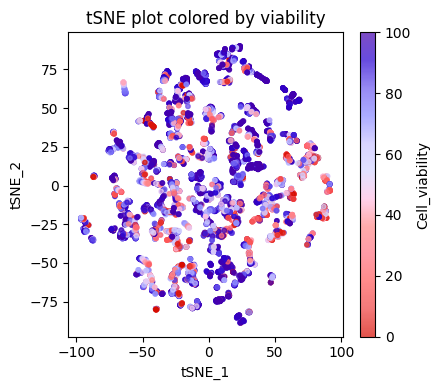

In [49]:
# Compute t-SNE embedding
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(RX2)

# Plot
fig, ax = plt.subplots(figsize=(4.5,4))
sc = ax.scatter(
    X_embedded[:,0], X_embedded[:,1],
    c=RY2, cmap = load_cmap("default_gsea", cmap_type="continuous", reverse=True),
    vmin=0, vmax=100,   # clip color scale
    s=10, alpha=0.7
)
plt.colorbar(sc, label='Cell_viability')

ax.set_xlabel('tSNE_1')
ax.set_ylabel('tSNE_2')
ax.set_title('tSNE plot colored by viability')
plt.tight_layout()

plt.show()

## Step 3: Build Machine Learning Modeling Pipeline

In [50]:
# Define models
models = {
    'CatBoost': (CatBoostRegressor(verbose=False, thread_count=1), catboost_parm_search),
    'GB': (GradientBoostingRegressor(), GB_parm_search),
    'RF': (RandomForestRegressor(), rf_parm_search),
    'XGB': (XGBRegressor(n_jobs=1), XGB_parm_search),
    'KNN': (KNeighborsRegressor(), KNN_parm_search),
    'SVM': (SVR(), SVM_parm_search),
    'NN': (MLPRegressor(max_iter=4000, early_stopping=True, n_iter_no_change=25, random_state=42), NN_parm_search),
    }

In [51]:
print(type(RX2))

<class 'pandas.core.frame.DataFrame'>


In [52]:
# Fit and transform only numerical features 
#'Diameter', 'Time', 'Concentration', 'Mol_weight', 'Electronegativity', 'Dh_median', 'ZP_median'
binary_features = [
    col for col in RX2.columns
    if set(RX2[col].dropna().unique()).issubset({0, 1})
]

numerical_features = [
    col for col in RX2.columns
    if col not in binary_features
]

In [54]:
warnings.filterwarnings("ignore", category=UserWarning, module="joblib")

results_RE = []

for model_name, (model, param_search) in models.items():
    print(f"Model: {model_name}")

    nested_results = nested_cv(RX2, RY2, model_name)

    final_pipeline, final_pipe_params = make_pipeline(model_name, model, param_search)
    inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)
    search_n_jobs = 1 if model_name == "CatBoost" else -1

    final_search = RandomizedSearchCV(
        estimator=final_pipeline,
        param_distributions=final_pipe_params,
        n_iter=100,
        cv=inner_cv,
        scoring="neg_mean_absolute_error",
        n_jobs=search_n_jobs,
        random_state=42,
        error_score=np.nan,
    )
    final_search.fit(RX2, RY2)

    final_model = final_search.best_estimator_
    final_params = final_search.best_params_
    dump(final_model, f"Viability93_{model_name}.joblib")
    
    # Flatten everything into one row for the DataFrame
    row = {"Model": model_name, "Best Params": final_params}
    for stage in ("train", "test"):
        for metric, (mean_val, std_val) in nested_results[stage].items():
            row[f"{stage.capitalize()} {metric} Mean"] = mean_val
            row[f"{stage.capitalize()} {metric} Std"] = std_val
    results_RE.append(row)

# Build and save the final DataFrame
Viability_results = pd.DataFrame(results_RE)
Viability_results.to_csv("ViabilityRE_93.csv", index=False)
print(Viability_results)

Model: CatBoost
Model: GB
Model: RF
Model: XGB
Model: KNN
Model: SVM
Model: NN
      Model                                        Best Params  \
0  CatBoost  {'bagging_temperature': 0.2332280724245278, 'd...   
1        GB  {'learning_rate': 0.21124547565947993, 'max_de...   
2        RF  {'bootstrap': False, 'max_depth': 31, 'max_fea...   
3       XGB  {'colsample_bytree': 0.9085081386743783, 'eta'...   
4       KNN  {'clf__n_neighbors': 2, 'clf__weights': 'dista...   
5       SVM  {'clf__C': 49.62066332418385, 'clf__epsilon': ...   
6        NN  {'clf__hidden_layer_sizes': (256, 200), 'clf__...   

   Train mse Mean  Train mse Std  Train rmse Mean  Train rmse Std  \
0       67.902679       2.757914         8.238610        0.167273   
1       56.432782       8.908922         7.490419        0.571322   
2       62.832208       2.649428         7.924908        0.167460   
3       69.840109       3.997077         8.353551        0.241442   
4       56.331059       4.457217         7.4995

# Download df for Best file use

In [53]:
Viability_dedup2.to_csv('Viability93_7012.csv', index=False)